In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("integrated_healthcare_dataset.csv")

In [3]:
df.head()

,ISO3,Country,Year,Population,Age_0_14_Pct,Age_65_Plus_Pct,Urban_Population_Pct,GDP_Per_Capita_PPP_2021,Secondary_Enrollment_Gross_Pct,Adult_Literacy_Rate,...,OOP_Pct_Current_Health_Exp,Financial_Hardship_Total_Pct,Large_Spending_Pct,Impoverishing_Spending_Pct,Q1_Poorest_Pct,Q2_Pct,Q3_Pct,Q4_Pct,Q5_Richest_Pct,Equity_Gap_Pct_Points
0,AFG,Afghanistan,1960,9035043.0,41.946754,2.823362,8.122551,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AFG,Afghanistan,1961,9214083.0,42.028588,2.809357,8.389595,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AFG,Afghanistan,1962,9404406.0,42.112814,2.792835,8.662664,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AFG,Afghanistan,1963,9604487.0,42.235952,2.775057,8.942709,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AFG,Afghanistan,1964,9814318.0,42.409539,2.757792,9.231134,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Dataset Shape:", df.shape)
print("Number of Countries:", df['ISO3'].nunique())
print("Number of Years:", df['Year'].nunique())
print("Year Range:", df['Year'].min(), "-", df['Year'].max())

Dataset Shape: (12855, 27)
Number of Countries: 196
Number of Years: 66
Year Range: 1960 - 2025


### 1.1 Dataset Overview

The integrated dataset contains 12,855 rows and 27 columns,
covering 196 countries over the period from 1960 to 2025.

df.dtypes

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12855 entries, 0 to 12854
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ISO3                            12855 non-null  object 
 1   Country                         12855 non-null  object 
 2   Year                            12855 non-null  int64  
 3   Population                      12774 non-null  float64
 4   Age_0_14_Pct                    12804 non-null  float64
 5   Age_65_Plus_Pct                 12804 non-null  float64
 6   Urban_Population_Pct            12804 non-null  float64
 7   GDP_Per_Capita_PPP_2021         6630 non-null   float64
 8   Secondary_Enrollment_Gross_Pct  6023 non-null   float64
 9   Adult_Literacy_Rate             1102 non-null   float64
 10  Doctors_Total                   4293 non-null   float64
 11  Doctors_Per_10k                 4280 non-null   float64
 12  Nurses_Midwives_Per_10k         

In [7]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2),
    'Available_Count': df.notnull().sum()
})
missing_summary

,Missing_Count,Missing_Percentage,Available_Count
ISO3,0,0.00,12855
Country,0,0.00,12855
Year,0,0.00,12855
Population,81,0.63,12774
Age_0_14_Pct,51,0.40,12804
Age_65_Plus_Pct,51,0.40,12804
Urban_Population_Pct,51,0.40,12804
GDP_Per_Capita_PPP_2021,6225,48.42,6630
Secondary_Enrollment_Gross_Pct,6832,53.15,6023
Adult_Literacy_Rate,11753,91.43,1102


### 1.3 Missing Values Analysis

The dataset contains substantial missing values across several indicators.

The main healthcare indicators have the following missing percentages:

- Doctors_Total: 66.60%
- Doctors_Per_10k: 66.71%
- Nurses_Midwives_Per_10k: 73.75%
- Hospital_Beds_Per_10k: 76.99%
- UHC_Service_Coverage_Index: 63.59%

Country identifiers and Year have no missing values.

Missing values will not be replaced with zero or estimated.
Each analysis will use only observations with available values
for the indicators being compared.

In [8]:
indicators = [
    'Doctors_Total',
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k',
    'Hospital_Beds_Per_10k',
    'UHC_Service_Coverage_Index'
]
coverage = []
for col in indicators:
    available = df[df[col].notna()]

    coverage.append({
        'Indicator': col,
        'Available_Values': available[col].count(),
        'First_Year': available['Year'].min(),
        'Last_Year': available['Year'].max()
    })
coverage_df = pd.DataFrame(coverage)
coverage_df

,Indicator,Available_Values,First_Year,Last_Year
0,Doctors_Total,4293,1971,2024
1,Doctors_Per_10k,4280,1971,2024
2,Nurses_Midwives_Per_10k,3374,1990,2023
3,Hospital_Beds_Per_10k,2958,2000,2023
4,UHC_Service_Coverage_Index,4680,2000,2023


### 1.4 Indicator Time Coverage

Healthcare indicators have different time coverage:

- Doctors data: 1971–2024.
- Nurses and Midwives data: 1990–2023.
- Hospital Beds data: 2000–2023.
- UHC data: 2000–2023.

The analysis period will depend on the overlapping
years available for each resource indicator and UHC.

In [9]:
resources = [
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k',
    'Hospital_Beds_Per_10k'
]
pairwise_results = []
for col in resources:
    pair = df[
        [col, 'UHC_Service_Coverage_Index', 'Country', 'Year']
    ].dropna()
    pairwise_results.append({
        'Resource_Indicator': col,
        'Shared_Observations': len(pair),
        'Countries': pair['Country'].nunique(),
        'First_Year': pair['Year'].min(),
        'Last_Year': pair['Year'].max()
    })
pairwise_df = pd.DataFrame(pairwise_results)
pairwise_df

,Resource_Indicator,Shared_Observations,Countries,First_Year,Last_Year
0,Doctors_Per_10k,2956,192,2000,2023
1,Nurses_Midwives_Per_10k,2839,194,2000,2023
2,Hospital_Beds_Per_10k,2958,193,2000,2023


In [10]:
workforce_columns = [
    'Doctors_Total',
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k'
]
workforce_stats = df[workforce_columns].describe().T
workforce_stats

,count,mean,std,min,25%,50%,75%,max
Doctors_Total,4293.0,67883.905427,226100.372836,3.00,3154.0000,13983.000,42702.000,4009658.00
Doctors_Per_10k,4280.0,21.005706,14.644311,0.13,8.2875,20.510,31.505,95.43
Nurses_Midwives_Per_10k,3374.0,49.338454,38.537319,0.47,15.8500,42.445,70.550,208.31


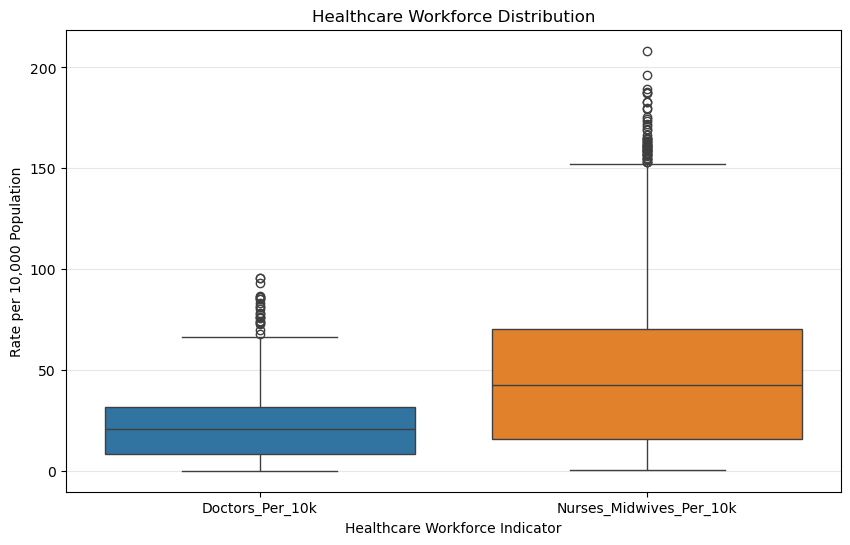

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

workforce_columns = [
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k'
]
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[workforce_columns])
plt.title('Healthcare Workforce Distribution')
plt.ylabel('Rate per 10,000 Population')
plt.xlabel('Healthcare Workforce Indicator')
plt.grid(axis='y', alpha=0.3)

plt.show()

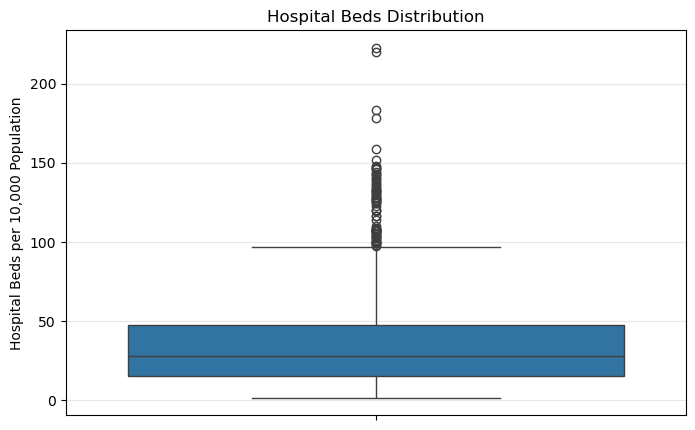

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Hospital_Beds_Per_10k'])
plt.title('Hospital Beds Distribution')
plt.ylabel('Hospital Beds per 10,000 Population')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [13]:
df['Hospital_Beds_Per_10k'].describe()

count    2958.000000
mean       34.477522
std        26.278789
min         1.540000
25%        14.900000
50%        27.735000
75%        47.722500
max       222.700000
Name: Hospital_Beds_Per_10k, dtype: float64

In [14]:
from scipy.stats import spearmanr
resources = [
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k',
    'Hospital_Beds_Per_10k'
]
results = []
for col in resources:
    pair = df[[col, 'UHC_Service_Coverage_Index']].dropna()

    correlation, p_value = spearmanr(
        pair[col],
        pair['UHC_Service_Coverage_Index']
    )
    results.append({
        'Resource': col,
        'Observations': len(pair),
        'Spearman_Correlation': correlation,
        'P_Value': p_value
    })
correlation_df = pd.DataFrame(results)
correlation_df

,Resource,Observations,Spearman_Correlation,P_Value
0,Doctors_Per_10k,2956,0.738383,0.000000e+00
1,Nurses_Midwives_Per_10k,2839,0.777108,0.000000e+00
2,Hospital_Beds_Per_10k,2958,0.489669,3.223817e-178


NameError: name 'os' is not defined

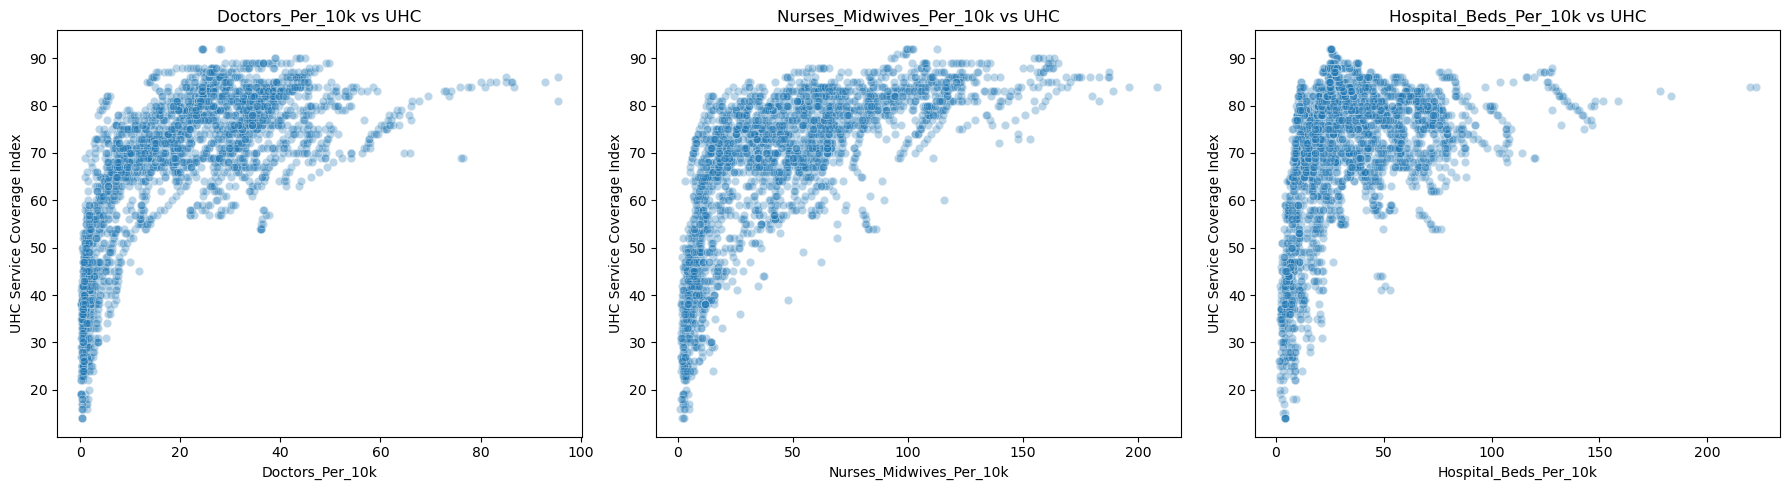

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(resources):
    pair = df[[col, 'UHC_Service_Coverage_Index']].dropna()
    sns.scatterplot(
        data=pair,
        x=col,
        y='UHC_Service_Coverage_Index',
        alpha=0.3,
        ax=axes[i]
    )
    axes[i].set_title(f'{col} vs UHC')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('UHC Service Coverage Index')
plt.tight_layout()
plt.savefig(
    os.path.join(output_folder, 'healthcare_resources_scatter.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [18]:
comparison_columns = [
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k',
    'Hospital_Beds_Per_10k',
    'UHC_Service_Coverage_Index'
]
yearly_coverage = (
    df.groupby('Year')
    .apply(
        lambda group: pd.Series({
            col: group.loc[group[col].notna(), 'ISO3'].nunique()
            for col in comparison_columns
        }),
        include_groups=False
    )
)
yearly_coverage.tail(15)

,Doctors_Per_10k,Nurses_Midwives_Per_10k,Hospital_Beds_Per_10k,UHC_Service_Coverage_Index
Year,,,,
2011,122,111,143,195
2012,125,112,140,195
2013,122,135,147,195
2014,125,146,145,195
2015,124,141,144,195
2016,130,143,142,195
2017,141,146,140,195
2018,154,173,139,195
2019,139,127,138,195


In [19]:
common_years = []

for year in range(2000, 2024):
    year_data = df[df['Year'] == year]

    complete_data = year_data.dropna(
        subset=comparison_columns
    )
    common_years.append({
        'Year': year,
        'Countries_With_All_Indicators': complete_data['ISO3'].nunique()
    })
common_years_df = pd.DataFrame(common_years)

common_years_df.sort_values(
    by='Countries_With_All_Indicators',
    ascending=False
).head(10)

,Year,Countries_With_All_Indicators
18,2018,115
17,2017,111
10,2010,108
14,2014,105
16,2016,104
15,2015,101
13,2013,98
19,2019,96
12,2012,95
8,2008,94


In [20]:
comparison_year = 2018

comparison_df = df[
    (df['Year'] == comparison_year)
].dropna(
    subset=comparison_columns
).copy()
print("Comparison Year:", comparison_year)
print("Number of Countries:", comparison_df['ISO3'].nunique())
print("Dataset Shape:", comparison_df.shape)
comparison_df[
    ['Country'] + comparison_columns
].head(10)

Comparison Year: 2018
Number of Countries: 115
Dataset Shape: (115, 27)


,Country,Doctors_Per_10k,Nurses_Midwives_Per_10k,Hospital_Beds_Per_10k,UHC_Service_Coverage_Index
58,Afghanistan,3.03,4.51,4.00,42.0
322,United Arab Emirates,26.05,59.01,15.98,83.0
388,Argentina,51.52,38.89,36.92,79.0
454,Armenia,28.36,46.07,41.76,70.0
652,Austria,95.43,71.29,72.71,81.0
718,Azerbaijan,32.68,57.96,39.47,65.0
850,Belgium,31.30,117.91,56.22,86.0
916,Benin,0.73,5.22,4.39,36.0
1048,Bangladesh,5.73,4.66,8.77,47.0
1114,Bulgaria,44.15,48.04,75.69,71.0


In [21]:
for col in comparison_columns:
    if col == 'UHC_Service_Coverage_Index':
        title = 'UHC Service Coverage'
    else:
        title = col

    print(f'\n===== {title} =====')

    print('\nTop 10 Countries:')
    display(
        comparison_df[['Country', col]]
        .sort_values(by=col, ascending=False)
        .head(10)
    )

    print('\nBottom 10 Countries:')
    display(
        comparison_df[['Country', col]]
        .sort_values(by=col, ascending=True)
        .head(10)
    )


===== Doctors_Per_10k =====

Top 10 Countries:


,Country,Doctors_Per_10k
652,Austria,95.43
2789,Cuba,85.05
4175,Georgia,76.48
4571,Greece,61.04
9481,Portugal,52.97
388,Argentina,51.52
6881,Lithuania,45.69
1378,Belarus,45.05
8623,Norway,44.65
7211,"Moldova, Republic of",44.36



Bottom 10 Countries:


,Country,Doctors_Per_10k
8333,Niger,0.37
11923,"Tanzania, United Republic of",0.50
916,Benin,0.73
11263,Togo,0.82
7937,Mozambique,0.85
3515,Eritrea,0.88
7607,Mali,1.20
9877,Rwanda,1.32
6485,Liberia,1.40
6023,Cambodia,2.11



===== Nurses_Midwives_Per_10k =====

Top 10 Countries:


,Country,Nurses_Midwives_Per_10k
2038,Switzerland,179.15
8623,Norway,158.82
5429,Iceland,154.69
5231,Ireland,128.68
3779,Finland,126.22
5759,Japan,119.75
3185,Denmark,118.17
850,Belgium,117.91
2987,Germany,117.43
10933,Sweden,116.56


... (6 outputs left out)


===== UHC Service Coverage =====

Top 10 Countries:


,Country,UHC_Service_Coverage_Index
1972,Canada,92.0
5429,Iceland,90.0
8821,New Zealand,89.0
6221,"Korea, Republic of",87.0
8623,Norway,87.0
4109,United Kingdom,87.0
12187,United States,87.0
2987,Germany,86.0
3779,Finland,86.0
2038,Switzerland,86.0



Bottom 10 Countries:


,Country,UHC_Service_Coverage_Index
8333,Niger,35.0
916,Benin,36.0
11263,Togo,39.0
3515,Eritrea,40.0
4967,Haiti,41.0
7607,Mali,41.0
11923,"Tanzania, United Republic of",42.0
58,Afghanistan,42.0
11527,Timor-Leste,44.0
6485,Liberia,46.0


In [22]:
display(
    comparison_df[['Country', 'UHC_Service_Coverage_Index']]
    .sort_values(
        by='UHC_Service_Coverage_Index',
        ascending=False
    )
    .head(10)
)

,Country,UHC_Service_Coverage_Index
1972,Canada,92.0
5429,Iceland,90.0
8821,New Zealand,89.0
6221,"Korea, Republic of",87.0
8623,Norway,87.0
4109,United Kingdom,87.0
12187,United States,87.0
2987,Germany,86.0
3779,Finland,86.0
2038,Switzerland,86.0


In [23]:
display(
    comparison_df[
        ['Country', 'Doctors_Per_10k']
    ]
    .sort_values(
        by='Doctors_Per_10k',
        ascending=False
    )
    .head(10)
)

,Country,Doctors_Per_10k
652,Austria,95.43
2789,Cuba,85.05
4175,Georgia,76.48
4571,Greece,61.04
9481,Portugal,52.97
388,Argentina,51.52
6881,Lithuania,45.69
1378,Belarus,45.05
8623,Norway,44.65
7211,"Moldova, Republic of",44.36


In [24]:
display(
    comparison_df[['Country', 'Doctors_Per_10k']]
    .sort_values(
        by='Doctors_Per_10k',
        ascending=True
    )
    .head(10)
)

,Country,Doctors_Per_10k
8333,Niger,0.37
11923,"Tanzania, United Republic of",0.50
916,Benin,0.73
11263,Togo,0.82
7937,Mozambique,0.85
3515,Eritrea,0.88
7607,Mali,1.20
9877,Rwanda,1.32
6485,Liberia,1.40
6023,Cambodia,2.11


In [25]:
display(
    comparison_df[['Country', 'Nurses_Midwives_Per_10k']]
    .sort_values(
        by='Nurses_Midwives_Per_10k',
        ascending=False
    )
    .head(10)
)

,Country,Nurses_Midwives_Per_10k
2038,Switzerland,179.15
8623,Norway,158.82
5429,Iceland,154.69
5231,Ireland,128.68
3779,Finland,126.22
5759,Japan,119.75
3185,Denmark,118.17
850,Belgium,117.91
2987,Germany,117.43
10933,Sweden,116.56


In [26]:
display(
    comparison_df[['Country', 'Nurses_Midwives_Per_10k']]
    .sort_values(
        by='Nurses_Midwives_Per_10k',
        ascending=True
    )
    .head(10)
)

,Country,Nurses_Midwives_Per_10k
8333,Niger,2.26
11263,Togo,3.92
4967,Haiti,4.04
7607,Mali,4.11
58,Afghanistan,4.51
1048,Bangladesh,4.66
7937,Mozambique,4.88
916,Benin,5.22
11923,"Tanzania, United Republic of",5.56
6485,Liberia,6.38


In [27]:
display(
    comparison_df[['Country', 'Hospital_Beds_Per_10k']]
    .sort_values(
        by='Hospital_Beds_Per_10k',
        ascending=False
    )
    .head(10)
)

,Country,Hospital_Beds_Per_10k
5759,Japan,129.30
6221,"Korea, Republic of",124.30
1378,Belarus,99.34
2987,Germany,79.39
7871,Mongolia,78.56
1114,Bulgaria,75.69
652,Austria,72.71
9811,Russian Federation,71.36
5033,Hungary,69.52
9745,Romania,69.24


In [28]:
display(
    comparison_df[['Country', 'Hospital_Beds_Per_10k']]
    .sort_values(
        by='Hospital_Beds_Per_10k',
        ascending=True
    )
    .head(10)
)

,Country,Hospital_Beds_Per_10k
8333,Niger,2.42
7607,Mali,2.47
8689,Nepal,2.91
58,Afghanistan,4.00
11527,Timor-Leste,4.15
11923,"Tanzania, United Republic of",4.35
4703,Guatemala,4.38
916,Benin,4.39
8953,Pakistan,4.99
11263,Togo,6.29


In [29]:
doctors_trend = (
    df.groupby('Year')
    .agg(
        Average_Doctors_Per_10k=('Doctors_Per_10k', 'mean'),
        Countries_Count=('ISO3', lambda x: x[df.loc[x.index, 'Doctors_Per_10k'].notna()].nunique())
    )
    .reset_index()
)
doctors_trend = doctors_trend[
    doctors_trend['Average_Doctors_Per_10k'].notna()
]

display(doctors_trend.tail(10))

,Year,Average_Doctors_Per_10k,Countries_Count
55,2015,20.974839,124
56,2016,21.197385,130
57,2017,21.581489,141
58,2018,20.938766,154
59,2019,22.568417,139
60,2020,21.668264,144
61,2021,23.491654,133
62,2022,22.253043,138
63,2023,23.588034,117
64,2024,14.705429,70


In [30]:
nurses_trend = (
    df.groupby('Year')
    .agg(
        Average_Nurses_Per_10k=('Nurses_Midwives_Per_10k', 'mean'),
        Countries_Count=(
            'ISO3',
            lambda x: x[
                df.loc[x.index, 'Nurses_Midwives_Per_10k'].notna()
            ].nunique()
        )
    )
    .reset_index()
)

nurses_trend = nurses_trend[
    nurses_trend['Average_Nurses_Per_10k'].notna()
]

display(nurses_trend.tail(10))

,Year,Average_Nurses_Per_10k,Countries_Count
54,2014,46.857945,146
55,2015,44.376809,141
56,2016,45.623636,143
57,2017,45.990137,146
58,2018,44.355116,173
59,2019,51.243071,127
60,2020,52.194729,129
61,2021,53.025556,117
62,2022,47.969603,126
63,2023,45.989867,75


In [31]:
beds_trend = (
    df.groupby('Year')
    .agg(
        Average_Beds_Per_10k=('Hospital_Beds_Per_10k', 'mean'),
        Countries_Count=(
            'ISO3',
            lambda x: x[
                df.loc[x.index, 'Hospital_Beds_Per_10k'].notna()
            ].nunique()
        )
    )
    .reset_index()
)

beds_trend = beds_trend[
    beds_trend['Average_Beds_Per_10k'].notna()
]

display(beds_trend.tail(10))

,Year,Average_Beds_Per_10k,Countries_Count
54,2014,32.443862,145
55,2015,31.398750,144
56,2016,31.580704,142
57,2017,31.351000,140
58,2018,32.112950,139
59,2019,31.459203,138
60,2020,32.230827,133
61,2021,33.270079,126
62,2022,33.767117,111
63,2023,32.065733,75


In [32]:
uhc_trend = (
    df.groupby('Year')
    .agg(
        Average_UHC_Index=('UHC_Service_Coverage_Index', 'mean'),
        Countries_Count=(
            'ISO3',
            lambda x: x[
                df.loc[x.index, 'UHC_Service_Coverage_Index'].notna()
            ].nunique()
        )
    )
    .reset_index()
)

uhc_trend = uhc_trend[
    uhc_trend['Average_UHC_Index'].notna()
]

display(uhc_trend.tail(10))

,Year,Average_UHC_Index,Countries_Count
54,2014,65.723077,195
55,2015,66.174359,195
56,2016,66.548718,195
57,2017,67.030769,195
58,2018,66.666667,195
59,2019,67.102564,195
60,2020,67.538462,195
61,2021,67.697436,195
62,2022,68.210256,195
63,2023,68.358974,195


In [33]:
trend_summary = (
    doctors_trend[['Year', 'Average_Doctors_Per_10k', 'Countries_Count']]
    .merge(
        nurses_trend[['Year', 'Average_Nurses_Per_10k', 'Countries_Count']],
        on='Year',
        how='outer',
        suffixes=('_Doctors', '_Nurses')
    )
    .merge(
        beds_trend[['Year', 'Average_Beds_Per_10k', 'Countries_Count']],
        on='Year',
        how='outer'
    )
    .merge(
        uhc_trend[['Year', 'Average_UHC_Index', 'Countries_Count']],
        on='Year',
        how='outer',
        suffixes=('', '_UHC')
    )
    .sort_values('Year')
)

display(trend_summary.tail(10))

,Year,Average_Doctors_Per_10k,Countries_Count_Doctors,Average_Nurses_Per_10k,Countries_Count_Nurses,Average_Beds_Per_10k,Countries_Count,Average_UHC_Index,Countries_Count_UHC
44,2015,20.974839,124,44.376809,141.0,31.398750,144.0,66.174359,195.0
45,2016,21.197385,130,45.623636,143.0,31.580704,142.0,66.548718,195.0
46,2017,21.581489,141,45.990137,146.0,31.351000,140.0,67.030769,195.0
47,2018,20.938766,154,44.355116,173.0,32.112950,139.0,66.666667,195.0
48,2019,22.568417,139,51.243071,127.0,31.459203,138.0,67.102564,195.0
49,2020,21.668264,144,52.194729,129.0,32.230827,133.0,67.538462,195.0
50,2021,23.491654,133,53.025556,117.0,33.270079,126.0,67.697436,195.0
51,2022,22.253043,138,47.969603,126.0,33.767117,111.0,68.210256,195.0
52,2023,23.588034,117,45.989867,75.0,32.065733,75.0,68.358974,195.0
53,2024,14.705429,70,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
import os
output_folder = (
    '04_Data_Analysis/03_Healthcare_Resources_Analysis_Shereen'
)
os.makedirs(output_folder, exist_ok=True)

trend_summary = trend_summary.rename(
    columns={
        'Countries_Count': 'Countries_Count_Beds'
    }
)
trend_summary.to_csv(
    os.path.join(output_folder, 'healthcare_resources_trends.csv'),
    index=False
)

print("Trend summary saved successfully.")

Trend summary saved successfully.


In [35]:
correlation_summary = correlation_df.copy()

def interpret_correlation(value):
    value = abs(value)

    if value >= 0.7:
        return 'Strong'
    elif value >= 0.4:
        return 'Moderate'
    elif value >= 0.2:
        return 'Weak'
    else:
        return 'Very Weak'

correlation_summary['Correlation_Strength'] = (
    correlation_summary['Spearman_Correlation']
    .apply(interpret_correlation)
)

correlation_summary['Relationship'] = (
    correlation_summary['Spearman_Correlation']
    .apply(lambda x: 'Positive' if x > 0 else 'Negative')
)

correlation_summary['Statistical_Significance'] = (
    correlation_summary['P_Value']
    .apply(lambda p: 'Significant' if p < 0.05 else 'Not Significant')
)
display(correlation_summary)

,Resource,Observations,Spearman_Correlation,P_Value,Correlation_Strength,Relationship,Statistical_Significance
0,Doctors_Per_10k,2956,0.738383,0.000000e+00,Strong,Positive,Significant
1,Nurses_Midwives_Per_10k,2839,0.777108,0.000000e+00,Strong,Positive,Significant
2,Hospital_Beds_Per_10k,2958,0.489669,3.223817e-178,Moderate,Positive,Significant


In [36]:
correlation_summary.to_csv(
    os.path.join(
        output_folder,
        'healthcare_resources_correlation_summary.csv'
    ),
    index=False
)

print("Correlation summary saved successfully.")

Correlation summary saved successfully.


In [37]:
comparison_df.to_csv(
    os.path.join(
        output_folder,
        'healthcare_resources_comparison_2018.csv'
    ),
    index=False
)

print("2018 comparison data saved successfully.")
print("Number of countries:", comparison_df['ISO3'].nunique())

2018 comparison data saved successfully.
Number of countries: 115


In [38]:
summary_columns = [
    'Doctors_Per_10k',
    'Nurses_Midwives_Per_10k',
    'Hospital_Beds_Per_10k',
    'UHC_Service_Coverage_Index'
]

descriptive_summary = df[summary_columns].describe().T

descriptive_summary.to_csv(
    os.path.join(
        output_folder,
        'healthcare_resources_analysis_summary.csv'
    )
)

display(descriptive_summary)

,count,mean,std,min,25%,50%,75%,max
Doctors_Per_10k,4280.0,21.005706,14.644311,0.13,8.2875,20.510,31.5050,95.43
Nurses_Midwives_Per_10k,3374.0,49.338454,38.537319,0.47,15.8500,42.445,70.5500,208.31
Hospital_Beds_Per_10k,2958.0,34.477522,26.278789,1.54,14.9000,27.735,47.7225,222.70
UHC_Service_Coverage_Index,4680.0,62.780769,18.485261,13.00,49.0000,69.000,77.0000,92.00


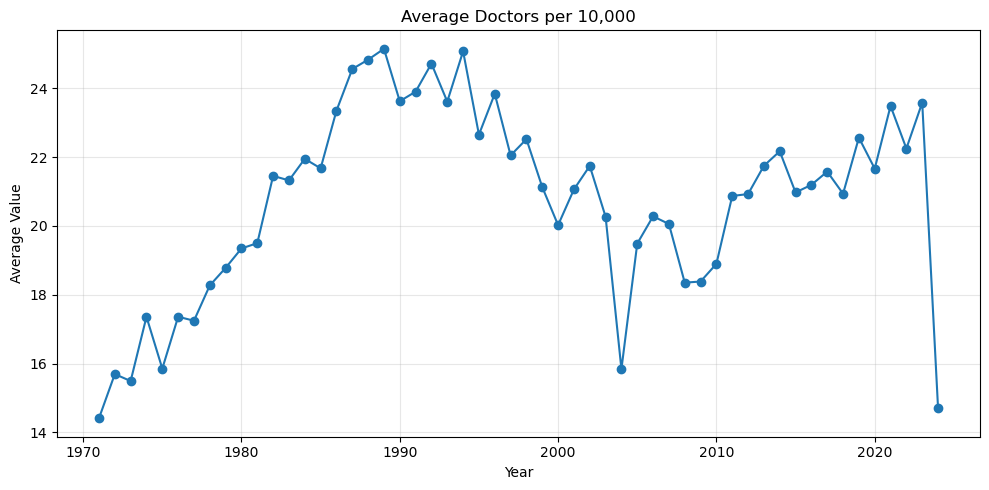

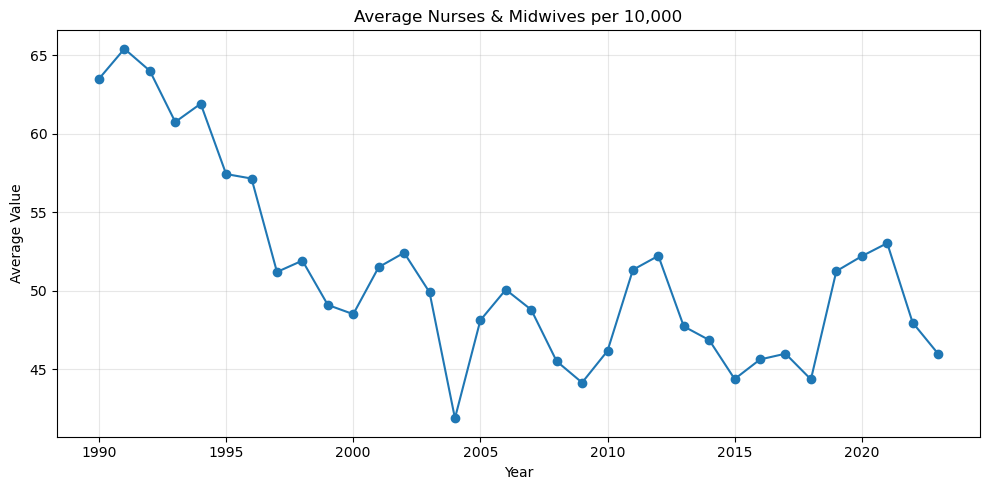

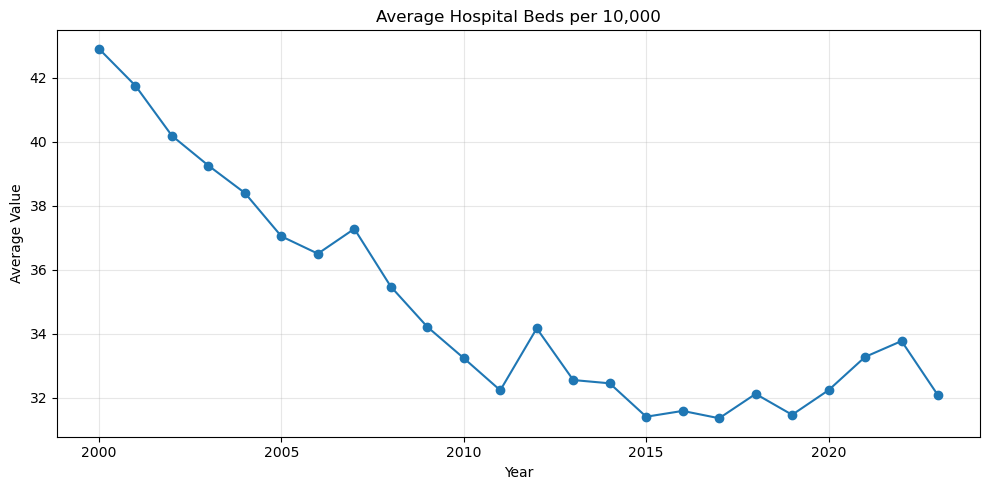

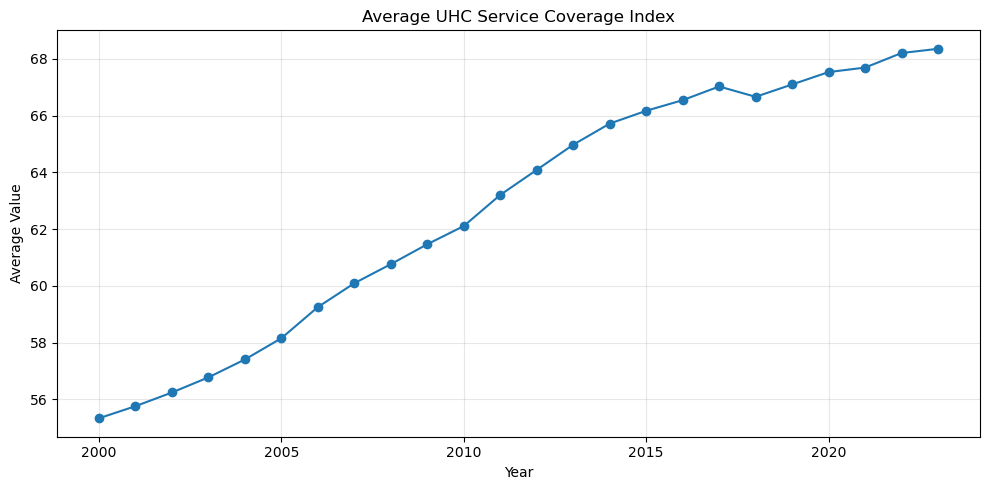

Trend charts saved successfully.


In [39]:
import matplotlib.pyplot as plt
import os

charts = [
    ('Average_Doctors_Per_10k', 'Average Doctors per 10,000', 'doctors_trend.png'),
    ('Average_Nurses_Per_10k', 'Average Nurses & Midwives per 10,000', 'nurses_trend.png'),
    ('Average_Beds_Per_10k', 'Average Hospital Beds per 10,000', 'beds_trend.png'),
    ('Average_UHC_Index', 'Average UHC Service Coverage Index', 'uhc_trend.png')
]

for column, title, filename in charts:
    plt.figure(figsize=(10, 5))
    plt.plot(trend_summary['Year'], trend_summary[column], marker='o')
    plt.title(title)
    plt.xlabel('Year')
    plt.ylabel('Average Value')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(os.path.join(output_folder, filename), dpi=300)
    plt.show()
    plt.close()

print("Trend charts saved successfully.")
